# Experiment 2: Fetching Data from a Weather Web API

**A52 Dipanshu Ambilkar**

In [1]:
# A52 Dipanshu Ambilkar
import requests
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns

In [2]:
url = "https://api.open-meteo.com/v1/forecast"
p = {"latitude": 18.52, "longitude": 73.85, "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation", "forecast_days": 7}
r = requests.get(url, params=p, timeout=30).json()
h = r["hourly"]

In [3]:
df = pd.DataFrame({
    "time": pd.to_datetime(h["time"]),
    "temp": h["temperature_2m"],
    "humidity": h["relative_humidity_2m"],
    "wind": h["wind_speed_10m"],
    "rain": h["precipitation"],
})
print(df.shape)
print(df.isnull().sum())
df = df.dropna()
print("Avg temp:", df["temp"].mean())
print("Max temp:", df["temp"].max(), " Min temp:", df["temp"].min())

(168, 5)
time        0
temp        0
humidity    0
wind        0
rain        0
dtype: int64
Avg temp: 28.245833333333334
Max temp: 33.9  Min temp: 22.3


In [4]:
df["date"] = df["time"].dt.date
daily = df.groupby("date").agg({"temp": "mean", "humidity": "mean", "wind": "mean", "rain": "sum"})
print(daily)

                 temp   humidity      wind  rain
date                                            
2026-10-09  27.850000  54.333333  5.875000   0.0
2026-10-10  28.208333  46.958333  5.287500   0.0
2026-10-11  28.450000  41.416667  6.529167   0.0
2026-10-12  28.054167  40.666667  6.670833   0.0
2026-10-13  28.120833  39.500000  6.854167   0.0
2026-10-14  28.525000  43.041667  7.520833   0.0
2026-10-15  28.512500  41.416667  5.762500   0.0


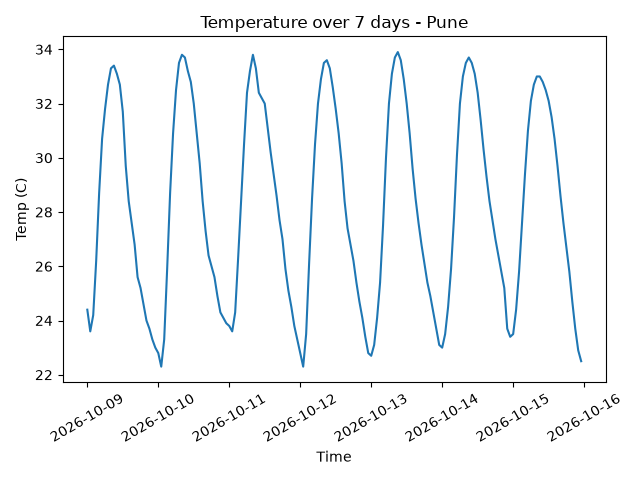

In [5]:
plt.plot(df["time"], df["temp"])
plt.title("Temperature over 7 days - Pune")
plt.xlabel("Time")
plt.ylabel("Temp (C)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("temp_line.png")
display(Image("temp_line.png"))
plt.close()

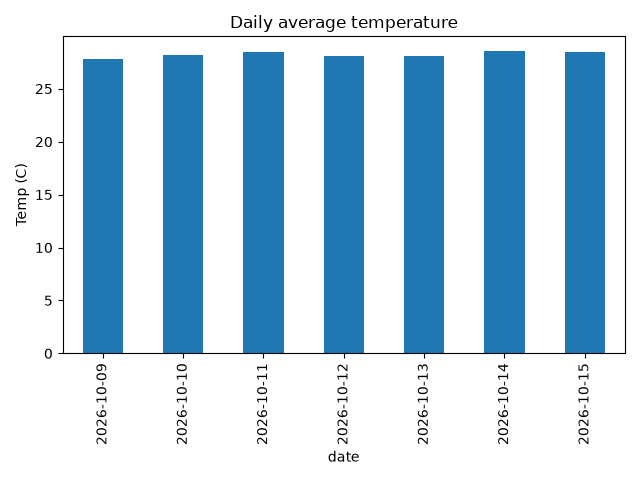

In [6]:
daily["temp"].plot(kind="bar")
plt.title("Daily average temperature")
plt.ylabel("Temp (C)")
plt.tight_layout()
plt.savefig("temp_bar.png")
display(Image("temp_bar.png"))
plt.close()

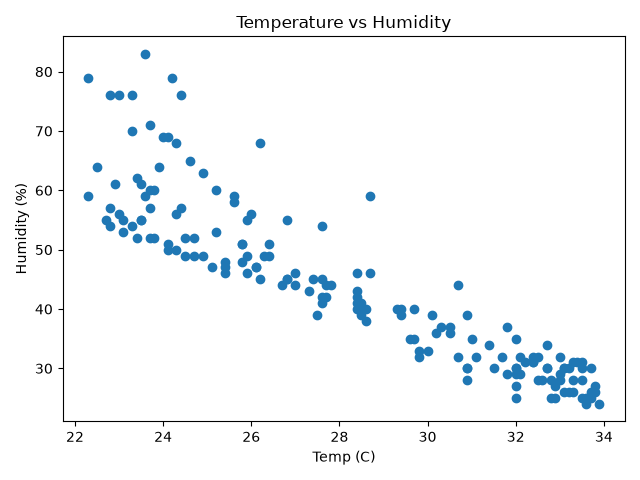

In [7]:
plt.scatter(df["temp"], df["humidity"])
plt.title("Temperature vs Humidity")
plt.xlabel("Temp (C)")
plt.ylabel("Humidity (%)")
plt.tight_layout()
plt.savefig("temp_humidity.png")
display(Image("temp_humidity.png"))
plt.close()

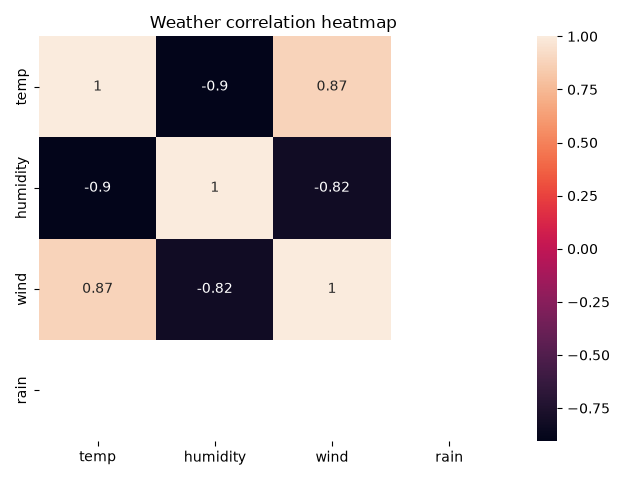

done


In [8]:
sns.heatmap(df[["temp", "humidity", "wind", "rain"]].corr(), annot=True)
plt.title("Weather correlation heatmap")
plt.tight_layout()
plt.savefig("weather_corr.png")
display(Image("weather_corr.png"))
plt.close()
print("done")